In [4]:
import pandas as pd
import numpy as np

columns = ['age','workclass','fnlwgt','education','education_num','marital_status',
           'occupation','relationship','race','sex','capital_gain','capital_loss',
           'hours_per_week','native_country','income']

df = pd.read_csv('adult.data', header=None, names=columns, na_values='?', skipinitialspace=True)

print(df.shape)
df.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
print(df.isnull().sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [6]:
for col in ['workclass', 'occupation', 'native_country']:
  df[col] = df[col].fillna(df[col].mode()[0])

  print(df.isnull().sum())

age                  0
workclass            0
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64
age                 0
workclass           0
fnlwgt              0
education           0
education_num       0
marital_status      0
occupation          0
relationship        0
race                0
sex                 0
capital_gain        0
capital_loss        0
hours_per_week      0
native_country    583
income              0
dtype: int64
age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Target variable: convert income text into 0/1
df['income'] = df['income'].str.strip()
y = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
X = df.drop(columns=['income'])

print('Class distribution (full data):')
print(y.value_counts(normalize=True))

# Step v, vi, vii: Train-test split, stratified, fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('\nClass distribution (train):')
print(y_train.value_counts(normalize=True))
print('\nClass distribution (test):')
print(y_test.value_counts(normalize=True))

# Identify which columns are text vs numbers
categorical_cols = X.select_dtypes(include='object').columns.tolist()
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
print('\nCategorical columns:', categorical_cols)
print('Numeric columns:', numeric_cols)

# Step iii, iv, viii: Encoding + scaling, fit ONLY on training data
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print('\nProcessed train shape:', X_train_processed.shape)
print('Processed test shape:', X_test_processed.shape)

Class distribution (full data):
income
0    0.75919
1    0.24081
Name: proportion, dtype: float64

Class distribution (train):
income
0    0.759175
1    0.240825
Name: proportion, dtype: float64

Class distribution (test):
income
0    0.759251
1    0.240749
Name: proportion, dtype: float64

Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Numeric columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Processed train shape: (26048, 105)
Processed test shape: (6513, 105)


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(random_state=42)
}

results = []

for name, model in models.items():
    # Naive Bayes and KNN need dense (non-sparse) arrays, not the sparse matrix one-hot encoding produces
    X_tr = X_train_processed.toarray() if hasattr(X_train_processed, 'toarray') else X_train_processed
    X_te = X_test_processed.toarray() if hasattr(X_test_processed, 'toarray') else X_test_processed

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred)
    })
    print(f'{name} done.')

results_df = pd.DataFrame(results)
print(results_df)

Logistic Regression done.
Decision Tree done.
KNN done.
Naive Bayes done.
Random Forest done.
                 Model  Accuracy       AUC  Precision    Recall  F1 Score  \
0  Logistic Regression  0.855827  0.907801   0.740627  0.617347  0.673391   
1        Decision Tree  0.810379  0.752525   0.599284  0.640944  0.619414   
2                  KNN  0.836634  0.867917   0.677465  0.613520  0.643909   
3          Naive Bayes  0.538154  0.749486   0.337398  0.952806  0.498332   
4        Random Forest  0.857516  0.906831   0.735641  0.637117  0.682843   

        MCC  
0  0.585834  
1  0.493833  
2  0.539363  
3  0.329438  
4  0.594115  


In [12]:
import matplotlib.pyplot as plt

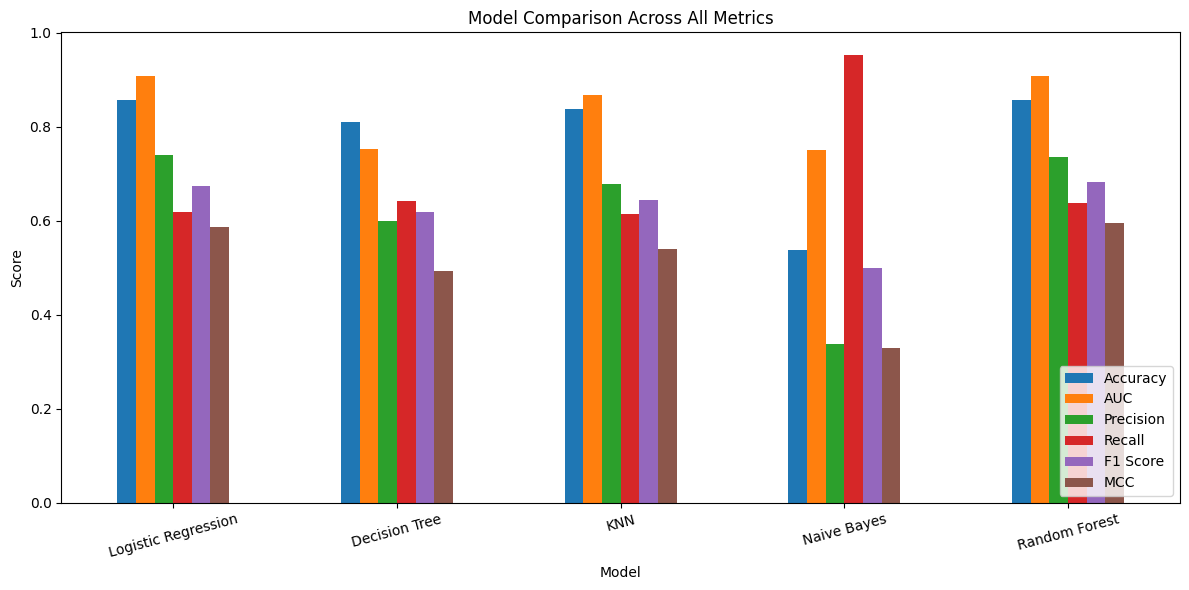

In [13]:
results_df.set_index('Model')[['Accuracy','AUC','Precision','Recall','F1 Score','MCC']].plot(
    kind='bar', figsize=(12,6)
)
plt.title('Model Comparison Across All Metrics')
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_comparison.png')
plt.show()

In [14]:
X_test.assign(income=y_test).to_csv('test_data.csv', index=False)